## Ice Task 1 PDAN8412

Exporting the cats and dogs images from the NumPy arrays back into image files, making sure each image keeps its correct class label.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import image_dataset_from_directory

#### Load the dataset

The test_set folder from the Kaggle Cat and Dog dataset has two sub folders, cats and dogs. TensorFlow uses the folder names as the class labels.

In [2]:
images = image_dataset_from_directory("test_set", image_size = (224, 224), batch_size = 32)

Found 2023 files belonging to 2 classes.


2026-09-30 16:08:31.792984: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-09-30 16:08:31.793005: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-09-30 16:08:31.793011: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1790777311.793020 5007906 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790777311.793047 5007906 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [3]:
class_names = images.class_names
print(class_names)

['cats', 'dogs']


#### Convert the dataset into NumPy arrays

In [4]:
all_images = []
all_labels = []

for image_batch, label_batch in images:
    all_images.append(image_batch.numpy())
    all_labels.append(label_batch.numpy())

imagesArray = np.concatenate(all_images, axis = 0)
labelsArray = np.concatenate(all_labels, axis = 0)

2026-09-30 16:08:32.207691: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [5]:
print(imagesArray.shape)
print(labelsArray.shape)

(2023, 224, 224, 3)
(2023,)


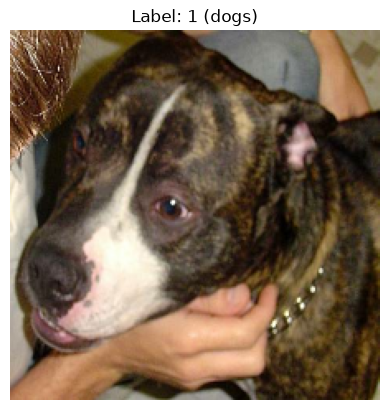

In [6]:
#Check one image with its label before exporting
plt.imshow(imagesArray[0] / 255.0)
plt.title(f"Label: {labelsArray[0]} ({class_names[labelsArray[0]]})")
plt.axis("off")
plt.show()

#### Export the images with their labels

Each image is saved into a folder named after its class, and the class name is also put in the file name. This way the label stays with the image even if it gets moved out of the folder.

In [7]:
output_folder = "exported_images"

#Create a folder for each class
for name in class_names:
    os.makedirs(os.path.join(output_folder, name), exist_ok = True)

for i, (image, label) in enumerate(zip(imagesArray, labelsArray)):

    image = image.astype("uint8")
    label_name = class_names[label]

    filename = os.path.join(output_folder, label_name, f"{label_name}_{i}.jpg")

    plt.imsave(filename, image)

print(f"{len(imagesArray)} images exported successfully")

2023 images exported successfully


#### Check that the export worked

In [8]:
#Count how many images ended up in each class folder
for name in class_names:
    count = len(os.listdir(os.path.join(output_folder, name)))
    print(f"{name}: {count} images")

cats: 1011 images
dogs: 1012 images


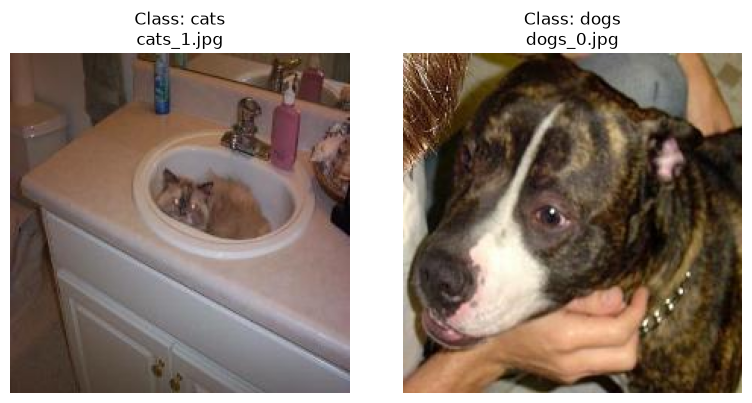

In [9]:
#Load a few exported images back in and show them with the label from the folder name
fig, axes = plt.subplots(1, 2, figsize = (8, 4))

for ax, name in zip(axes, class_names):
    first_file = sorted(os.listdir(os.path.join(output_folder, name)))[0]
    img = plt.imread(os.path.join(output_folder, name, first_file))

    ax.imshow(img)
    ax.set_title(f"Class: {name}\n{first_file}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Summary

The images were loaded from the dataset, turned into NumPy arrays and then saved back out as jpg files. Each one went into either the cats or dogs folder based on its label, and the class name was added to the file name too, so every exported image is still linked to the right class.